In [1]:
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'  # mixed precision makes training faster on the GPU
print('Device:', device)

Device: cuda


In [2]:
# ToTensor() scales pixels to [0, 1]. PyTorch uses integer labels with
# CrossEntropyLoss, so one-hot encoding is not needed.
plain_transform = transforms.ToTensor()

train_data = datasets.CIFAR10(root='./data', train=True, download=True, transform=plain_transform)
test_data = datasets.CIFAR10(root='./data', train=False, download=True, transform=plain_transform)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True, num_workers=2)
test_loader = DataLoader(test_data, batch_size=256, shuffle=False, num_workers=2)

class_names = train_data.classes
print('Classes:', class_names)
print('Training images:', len(train_data))
print('Test images:', len(test_data))

100%|██████████| 170M/170M [44:43<00:00, 63.5kB/s]


Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training images: 50000
Test images: 10000


In [3]:
class TransferModel(nn.Module):
    # Pretrained base + new classification layers (Flatten -> Dense 512 -> Dense 10)
    def __init__(self, base, n_features, input_size=None, dropout=0.0):
        super().__init__()
        if input_size:
            self.resize = nn.Upsample(size=(input_size, input_size), mode='bilinear', align_corners=False)
        else:
            self.resize = nn.Identity()
        self.base = base
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(n_features, 512), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(512, 10)
        )

    def forward(self, x):
        return self.head(self.base(self.resize(x)))


def vgg16_base():
    # Convolutional part only (same as include_top=False in Keras)
    return models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1).features


def resnet50_base():
    # Everything except the final ImageNet classification layer
    resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    return nn.Sequential(*list(resnet.children())[:-1])


def freeze(module):
    for param in module.parameters():
        param.requires_grad = False


def unfreeze(module):
    for param in module.parameters():
        param.requires_grad = True


def trainable_params(model):
    return [p for p in model.parameters() if p.requires_grad]


def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


criterion = nn.CrossEntropyLoss()


def evaluate(model, loader):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad(), torch.autocast(device_type=device.type, enabled=use_amp):
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            total_loss += criterion(outputs, labels).item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total


def train_model(model, optimizer, train_loader, test_loader, epochs=10, patience=None):
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    best_loss, best_weights, wait = float('inf'), None, 0
    start = time.time()

    for epoch in range(epochs):
        model.train()
        # Frozen BatchNorm layers stay in inference mode (same as Keras)
        for m in model.modules():
            if isinstance(m, nn.BatchNorm2d) and not m.weight.requires_grad:
                m.eval()

        total_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            with torch.autocast(device_type=device.type, enabled=use_amp):
                outputs = model(images)
                loss = criterion(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        val_loss, val_acc = evaluate(model, test_loader)
        history['loss'].append(total_loss / total)
        history['accuracy'].append(correct / total)
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(val_acc)
        print(f"Epoch {epoch + 1}/{epochs} - loss: {total_loss / total:.4f} - accuracy: {correct / total:.4f}"
              f" - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}")

        # Early stopping
        if patience is not None:
            if val_loss < best_loss:
                best_loss, best_weights, wait = val_loss, copy.deepcopy(model.state_dict()), 0
            else:
                wait += 1
                if wait >= patience:
                    print(f"Early stopping at epoch {epoch + 1}")
                    break

    if best_weights is not None:
        model.load_state_dict(best_weights)
    history['time'] = time.time() - start
    return history


def plot_history(history, title=''):
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history['accuracy'], label='Train Accuracy')
    plt.plot(history['val_accuracy'], label='Val Accuracy')
    plt.title(f'Accuracy - {title}')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid()

    plt.subplot(1, 2, 2)
    plt.plot(history['loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Val Loss')
    plt.title(f'Loss - {title}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid()
    plt.show()


results = []
all_histories = {}


def record(name, model, history, loader):
    _, acc = evaluate(model, loader)
    results.append((name, count_trainable(model), acc, len(history['loss']), history['time']))
    all_histories[name] = history
    return acc

In [4]:
vgg_base = vgg16_base()
freeze(vgg_base)

model_feature_extraction = TransferModel(vgg_base, 512).to(device)
print('Trainable parameters:', count_trainable(model_feature_extraction))

optimizer = optim.Adam(trainable_params(model_feature_extraction), lr=0.001)
history_feature_extraction = train_model(model_feature_extraction, optimizer, train_loader, test_loader, epochs=10)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 172MB/s]


Trainable parameters: 267786
Epoch 1/10 - loss: 1.2092 - accuracy: 0.5759 - val_loss: 1.1250 - val_accuracy: 0.6059
Epoch 2/10 - loss: 1.0459 - accuracy: 0.6310 - val_loss: 1.0782 - val_accuracy: 0.6227
Epoch 3/10 - loss: 0.9600 - accuracy: 0.6615 - val_loss: 1.0573 - val_accuracy: 0.6324
Epoch 4/10 - loss: 0.8820 - accuracy: 0.6888 - val_loss: 1.0570 - val_accuracy: 0.6365
Epoch 5/10 - loss: 0.8085 - accuracy: 0.7161 - val_loss: 1.0686 - val_accuracy: 0.6360
Epoch 6/10 - loss: 0.7386 - accuracy: 0.7401 - val_loss: 1.0657 - val_accuracy: 0.6424
Epoch 7/10 - loss: 0.6675 - accuracy: 0.7659 - val_loss: 1.1090 - val_accuracy: 0.6359
Epoch 8/10 - loss: 0.6042 - accuracy: 0.7896 - val_loss: 1.1438 - val_accuracy: 0.6341
Epoch 9/10 - loss: 0.5391 - accuracy: 0.8143 - val_loss: 1.1784 - val_accuracy: 0.6311
Epoch 10/10 - loss: 0.4843 - accuracy: 0.8333 - val_loss: 1.2537 - val_accuracy: 0.6307


In [ ]:
resnet_base = resnet50_base()
freeze(resnet_base)

model_finetune = TransferModel(resnet_base, 2048).to(device)

# Unfreeze the last 5 layers. In Keras these are the last conv + batch norm
# (plus add/relu layers with no weights) of the final ResNet50 block.
last_block = resnet_base[-2][-1]
unfreeze(last_block.conv3)
unfreeze(last_block.bn3)
print('Trainable parameters:', count_trainable(model_finetune))

optimizer = optim.Adam(trainable_params(model_finetune), lr=1e-5)
history_finetune = train_model(model_finetune, optimizer, train_loader, test_loader, epochs=10)

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 170MB/s]


Trainable parameters: 2106890
Epoch 1/10 - loss: 1.6362 - accuracy: 0.4510 - val_loss: 1.3772 - val_accuracy: 0.5281
Epoch 2/10 - loss: 1.3113 - accuracy: 0.5476 - val_loss: 1.2641 - val_accuracy: 0.5647
Epoch 3/10 - loss: 1.2278 - accuracy: 0.5756 - val_loss: 1.2162 - val_accuracy: 0.5791
Epoch 4/10 - loss: 1.1764 - accuracy: 0.5937 - val_loss: 1.1850 - val_accuracy: 0.5875
Epoch 5/10 - loss: 1.1393 - accuracy: 0.6066 - val_loss: 1.1636 - val_accuracy: 0.5979
Epoch 6/10 - loss: 1.1075 - accuracy: 0.6189 - val_loss: 1.1464 - val_accuracy: 0.6043
Epoch 7/10 - loss: 1.0814 - accuracy: 0.6281 - val_loss: 1.1276 - val_accuracy: 0.6096


In [ ]:
loss_feature_extraction, acc_feature_extraction = evaluate(model_feature_extraction, test_loader)
loss_finetune, acc_finetune = evaluate(model_finetune, test_loader)

print(f"Feature Extraction Accuracy: {acc_feature_extraction * 100:.2f}%")
print(f"Fine-Tuning Accuracy: {acc_finetune * 100:.2f}%")

record('VGG16 feature extraction', model_feature_extraction, history_feature_extraction, test_loader)
record('ResNet50 fine-tuning (tutorial)', model_finetune, history_finetune, test_loader)

plot_history(history_feature_extraction, 'VGG16 Feature Extraction')
plot_history(history_finetune, 'ResNet50 Fine-Tuning (Tutorial)')

## Task - Improved fine-tuning of ResNet50

In [ ]:
# Improvements:
# 1. Preprocessing: ImageNet normalization and resizing images from 32x32 to 128x128
# 2. Data augmentation (random crop + flip) to prevent overfitting
# 3. Unfreeze more layers (the whole of layer3 and layer4)
# 4. Higher learning rate for the new layers (1e-3) than for the pretrained ones (1e-4)
# 5. Dropout in the classifier and weight decay
# 6. Early stopping
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_transform_aug = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])
test_transform_norm = transforms.Compose([transforms.ToTensor(), transforms.Normalize(mean, std)])

train_data_aug = datasets.CIFAR10(root='./data', train=True, download=True, transform=train_transform_aug)
test_data_norm = datasets.CIFAR10(root='./data', train=False, download=True, transform=test_transform_norm)
train_loader_aug = DataLoader(train_data_aug, batch_size=64, shuffle=True, num_workers=2)
test_loader_norm = DataLoader(test_data_norm, batch_size=256, shuffle=False, num_workers=2)

improved_base = resnet50_base()
freeze(improved_base)
unfreeze(improved_base[-3])  # layer3
unfreeze(improved_base[-2])  # layer4

model_improved = TransferModel(improved_base, 2048, input_size=128, dropout=0.5).to(device)
print('Trainable parameters:', count_trainable(model_improved))

optimizer = optim.Adam([
    {'params': trainable_params(improved_base), 'lr': 1e-4},
    {'params': model_improved.head.parameters(), 'lr': 1e-3}
], weight_decay=1e-4)

history_improved = train_model(model_improved, optimizer, train_loader_aug, test_loader_norm,
                               epochs=12, patience=3)

acc_improved = record('ResNet50 fine-tuning (improved)', model_improved, history_improved, test_loader_norm)
print(f"Improved Fine-Tuning Accuracy: {acc_improved * 100:.2f}%")
plot_history(history_improved, 'ResNet50 Fine-Tuning (Improved)')

Trainable parameters: 23117322
Epoch 1/12 - loss: 0.3590 - accuracy: 0.8878 - val_loss: 0.1955 - val_accuracy: 0.9350
Epoch 2/12 - loss: 0.2073 - accuracy: 0.9345 - val_loss: 0.1817 - val_accuracy: 0.9453
Epoch 3/12 - loss: 0.1752 - accuracy: 0.9458 - val_loss: 0.1822 - val_accuracy: 0.9451
Epoch 4/12 - loss: 0.1401 - accuracy: 0.9563 - val_loss: 0.1905 - val_accuracy: 0.9501
Epoch 5/12 - loss: 0.1438 - accuracy: 0.9577 - val_loss: 0.1990 - val_accuracy: 0.9460
Early stopping at epoch 5


## Task - Feature extraction with ResNet50 vs custom model vs VGG16

In [ ]:
# Feature extraction with ResNet50
print("Training: ResNet50 feature extraction")
fe_resnet_base = resnet50_base()
freeze(fe_resnet_base)
model_fe_resnet = TransferModel(fe_resnet_base, 2048).to(device)
optimizer = optim.Adam(trainable_params(model_fe_resnet), lr=0.001)
history_fe_resnet = train_model(model_fe_resnet, optimizer, train_loader, test_loader, epochs=10)
record('ResNet50 feature extraction', model_fe_resnet, history_fe_resnet, test_loader)

# Custom CNN trained from scratch (the CNN from Tutorial 5)
print("\nTraining: Custom CNN")
custom_model = nn.Sequential(
    nn.Conv2d(3, 32, 3), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(64, 64, 3), nn.ReLU(),
    nn.Flatten(),
    nn.Linear(64 * 4 * 4, 64), nn.ReLU(),
    nn.Linear(64, 10)
).to(device)
optimizer = optim.Adam(custom_model.parameters(), lr=0.001)
history_custom = train_model(custom_model, optimizer, train_loader, test_loader, epochs=10)
record('Custom CNN (from scratch)', custom_model, history_custom, test_loader)

compare = ['ResNet50 feature extraction', 'Custom CNN (from scratch)', 'VGG16 feature extraction']
plt.figure(figsize=(8, 5))
for name in compare:
    plt.plot(all_histories[name]['val_accuracy'], label=name)
plt.title('Feature Extraction: ResNet50 vs Custom CNN vs VGG16')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid()
plt.show()

Training: ResNet50 feature extraction
Epoch 1/10 - loss: 1.2358 - accuracy: 0.5644 - val_loss: 1.1320 - val_accuracy: 0.6021
Epoch 2/10 - loss: 1.0499 - accuracy: 0.6282 - val_loss: 1.0599 - val_accuracy: 0.6250
Epoch 3/10 - loss: 0.9615 - accuracy: 0.6606 - val_loss: 1.0692 - val_accuracy: 0.6329
Epoch 4/10 - loss: 0.8866 - accuracy: 0.6842 - val_loss: 1.0508 - val_accuracy: 0.6387
Epoch 5/10 - loss: 0.8192 - accuracy: 0.7067 - val_loss: 1.0610 - val_accuracy: 0.6400
Epoch 6/10 - loss: 0.7423 - accuracy: 0.7363 - val_loss: 1.0921 - val_accuracy: 0.6393
Epoch 7/10 - loss: 0.6725 - accuracy: 0.7598 - val_loss: 1.1465 - val_accuracy: 0.6245
Epoch 8/10 - loss: 0.6099 - accuracy: 0.7816 - val_loss: 1.1812 - val_accuracy: 0.6301
Epoch 9/10 - loss: 0.5377 - accuracy: 0.8071 - val_loss: 1.2189 - val_accuracy: 0.6323
Epoch 10/10 - loss: 0.4726 - accuracy: 0.8297 - val_loss: 1.2518 - val_accuracy: 0.6370

Training: Custom CNN
Epoch 1/10 - loss: 1.6865 - accuracy: 0.3740 - val_loss: 1.4514 - val

## Task - Fine-tuning with VGG16

Trainable parameters: 7347210
Epoch 1/10 - loss: 0.8842 - accuracy: 0.6894 - val_loss: 0.7085 - val_accuracy: 0.7559
Epoch 2/10 - loss: 0.6076 - accuracy: 0.7867 - val_loss: 0.6788 - val_accuracy: 0.7614
Epoch 3/10 - loss: 0.4838 - accuracy: 0.8293 - val_loss: 0.6225 - val_accuracy: 0.7862
Epoch 4/10 - loss: 0.3675 - accuracy: 0.8699 - val_loss: 0.6384 - val_accuracy: 0.7843
Epoch 5/10 - loss: 0.2627 - accuracy: 0.9070 - val_loss: 0.7099 - val_accuracy: 0.7821
Epoch 6/10 - loss: 0.1716 - accuracy: 0.9396 - val_loss: 0.7559 - val_accuracy: 0.7922
Epoch 7/10 - loss: 0.1139 - accuracy: 0.9612 - val_loss: 0.8570 - val_accuracy: 0.7897
Epoch 8/10 - loss: 0.0767 - accuracy: 0.9734 - val_loss: 0.9744 - val_accuracy: 0.7835
Epoch 9/10 - loss: 0.0679 - accuracy: 0.9775 - val_loss: 1.0068 - val_accuracy: 0.7845
Epoch 10/10 - loss: 0.0491 - accuracy: 0.9831 - val_loss: 1.1058 - val_accuracy: 0.7845


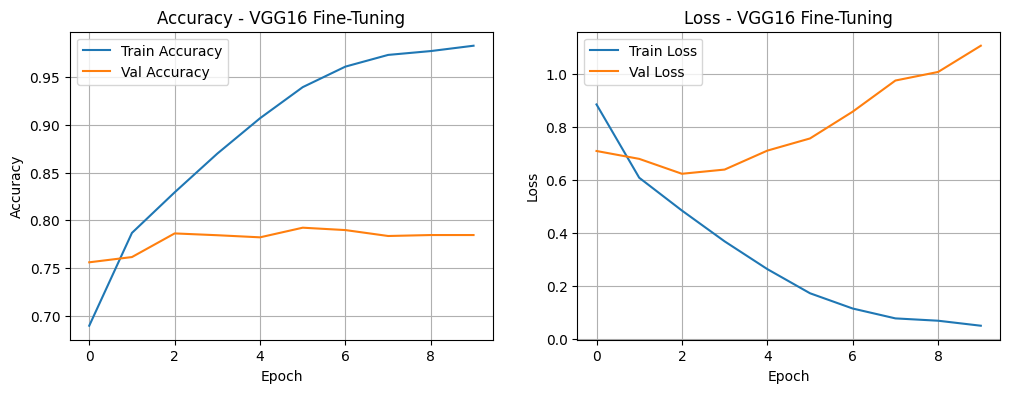

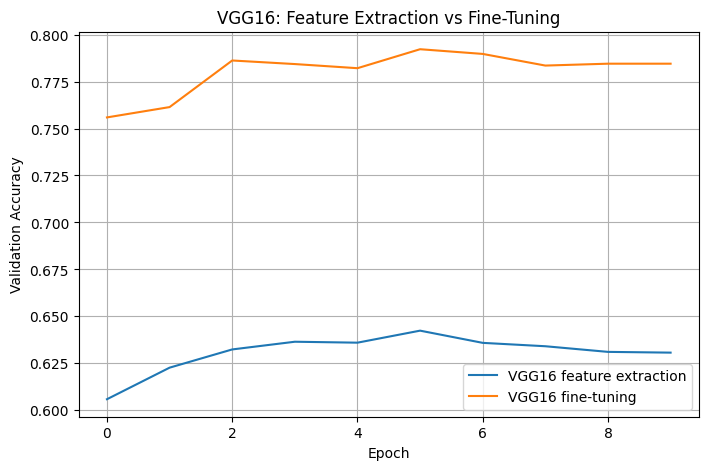

In [9]:
ft_vgg_base = vgg16_base()
freeze(ft_vgg_base)
unfreeze(ft_vgg_base[24:])  # last convolution block of VGG16

model_ft_vgg = TransferModel(ft_vgg_base, 512).to(device)
print('Trainable parameters:', count_trainable(model_ft_vgg))

optimizer = optim.Adam(trainable_params(model_ft_vgg), lr=1e-4)
history_ft_vgg = train_model(model_ft_vgg, optimizer, train_loader, test_loader, epochs=10)
record('VGG16 fine-tuning', model_ft_vgg, history_ft_vgg, test_loader)

plot_history(history_ft_vgg, 'VGG16 Fine-Tuning')

plt.figure(figsize=(8, 5))
for name in ['VGG16 feature extraction', 'VGG16 fine-tuning']:
    plt.plot(all_histories[name]['val_accuracy'], label=name)
plt.title('VGG16: Feature Extraction vs Fine-Tuning')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid()
plt.show()

Model                               Trainable params  Test acc  Epochs  Time (s)
VGG16 feature extraction                     267,786    0.6307      10     126.8
ResNet50 fine-tuning (tutorial)            2,106,890    0.6200      10     195.1
ResNet50 fine-tuning (improved)           23,117,322    0.9453       5     286.0
ResNet50 feature extraction                1,054,218    0.6370      10     185.5
Custom CNN (from scratch)                    122,570    0.6575      10     119.1
VGG16 fine-tuning                          7,347,210    0.7845      10     137.1


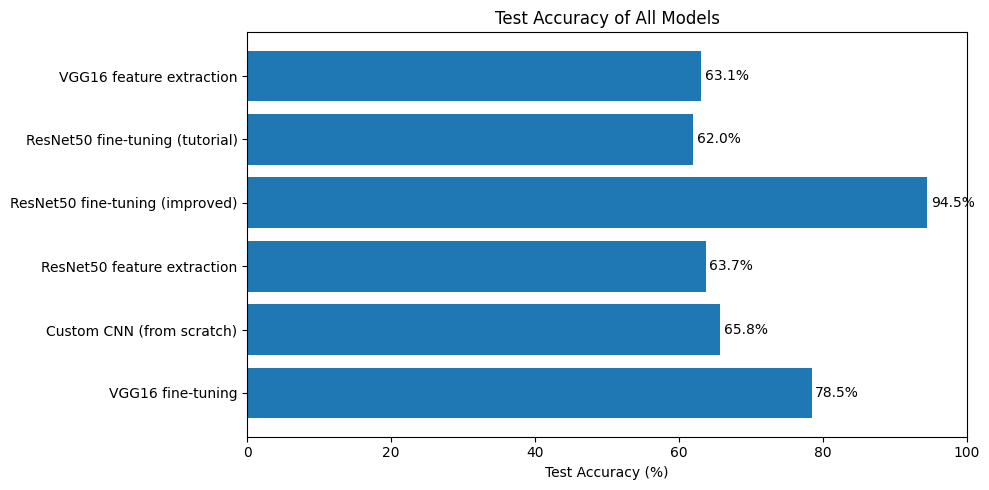

In [10]:
print(f"{'Model':34} {'Trainable params':>17} {'Test acc':>9} {'Epochs':>7} {'Time (s)':>9}")
for name, params, acc, epochs, t in results:
    print(f"{name:34} {params:17,} {acc:9.4f} {epochs:7} {t:9.1f}")

names = [r[0] for r in results]
accs = [r[2] * 100 for r in results]
plt.figure(figsize=(10, 5))
plt.barh(names[::-1], accs[::-1])
for i, acc in enumerate(accs[::-1]):
    plt.text(acc + 0.5, i, f'{acc:.1f}%', va='center')
plt.xlim(0, 100)
plt.xlabel('Test Accuracy (%)')
plt.title('Test Accuracy of All Models')
plt.tight_layout()
plt.show()